# 1. Volume Forecast and Production Planning: LPG B2C and Canisters

The business has three lines:

| Line | Customers | Unit | Planned with |
|---|---|---|---|
| **LPG B2C** | dealers | cylinders (2.7 / 11 / 22 / 50 kg) | **forecast (this notebook)** |
| **Canister** | canister distributors | cases (28 cans x 220 g) | **forecast (this notebook)** |
| **LPG B2B** | restaurants, hotels, industry | cylinders | **SPANCOP sales pipeline** (committed orders) |

**Business questions**
1. How much will LPG B2C dealers and canister distributors order from each plant in the next 4 weeks?
2. How many cylinders of each size, and how many canister cases, should each plant prepare?
3. Would a forecast-based plan reduce stockouts compared with the current rule (produce last month's average)?

> **Data note:** all data is **simulated** to mirror the structure of real plant gate logs
> (see `src/lpg/simulate.py`). No company data is used.

In [1]:
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
DATA = ROOT / "data" / "simulated"
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from lpg.forecasting import FEATURES, HORIZON, add_features, fit_lgbm, predict_lgbm, wape, weekly_demand
from lpg.simulate import CANISTER_CASE_KG, CYL_SIZES

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.float_format", "{:,.1f}".format)

FORECAST_LINES = ["B2C", "Canister"]          # segment codes we forecast
LABEL = {"B2C": "LPG B2C", "B2B": "LPG B2B", "Canister": "Canister"}

## 1.1 The data: plant gate log

Each row is one visit to a plant. `total_kg` is what was withdrawn; `order_kg` is what the customer
came for. They differ when the plant had **no stock**. Canister quantities are in cases.

In [2]:
visits = pd.read_csv(DATA / "plant_visits.csv", parse_dates=["date"])
print(f"{len(visits):,} visits, {visits['date'].min().date()} to {visits['date'].max().date()}")
visits.groupby("product_line").agg(visits=("visit_id", "size"), accounts=("account_id", "nunique"))

60,328 visits, 2023-01-02 to 2025-12-31


,visits,accounts
product_line,,
Canister,11558,176
LPG B2B,10555,109
LPG B2C,38215,334


## 1.2 Volume by business line

In [3]:
v = visits.assign(year=visits["date"].dt.year)
lpg = v[v["segment"] != "Canister"].pivot_table(index="year", columns="product_line", values="total_kg", aggfunc="sum") / 1e6
can = v[v["segment"] == "Canister"].groupby("year")["qty_canister_case"].sum() / 1000
vol = lpg.assign(**{"Canister ('000 cases)": can})
for c in vol.columns:
    vol[f"{c} YoY"] = (vol[c].pct_change() * 100).map(lambda x: "" if np.isnan(x) else f"{x:+.0f}%")
print("LPG in thousand tonnes (kt); canisters in thousand cases")
vol[sorted(vol.columns)]

LPG in thousand tonnes (kt); canisters in thousand cases


product_line,Canister ('000 cases),Canister ('000 cases) YoY,LPG B2B,LPG B2B YoY,LPG B2C,LPG B2C YoY
year,,,,,,
2023,505.2,,3.7,,13.0,
2024,593.5,+17%,4.0,+9%,15.3,+17%
2025,661.6,+11%,4.7,+16%,17.3,+13%


In [4]:
wd = v[(v["withdrew"] == 1) & (v["segment"] != "Canister")]
cyl = wd.groupby("product_line")[list(CYL_SIZES)].sum()
print("LPG cylinder mix (% of cylinders withdrawn)")
(cyl.div(cyl.sum(axis=1), axis=0) * 100).rename(columns=lambda c: c.replace("qty_", "").replace("_", "."))

LPG cylinder mix (% of cylinders withdrawn)


,2.7kg,11kg,22kg,50kg
product_line,,,,
LPG B2B,0.0,42.8,3.9,53.2
LPG B2C,18.3,78.7,1.9,1.2


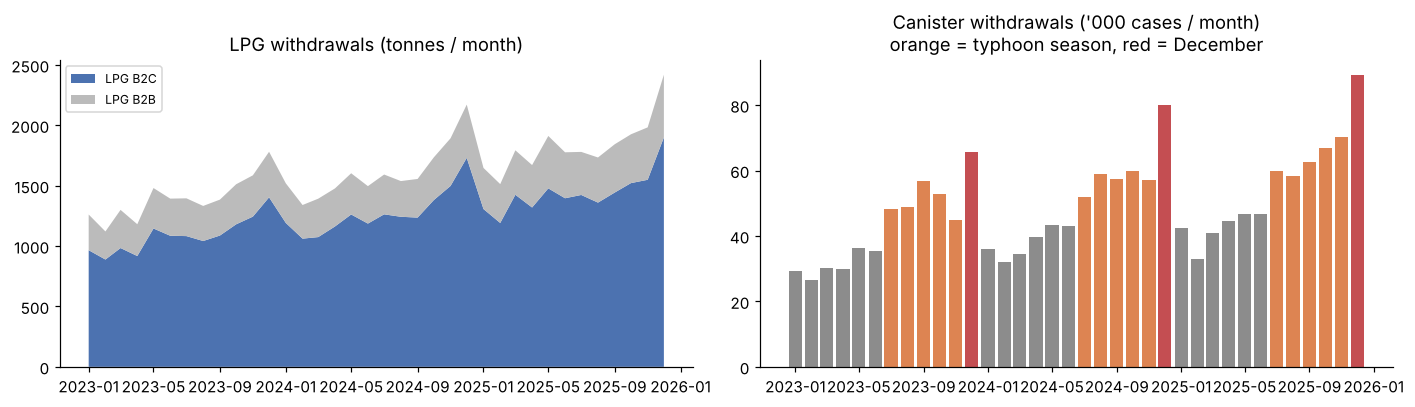

In [5]:
m = v.groupby([pd.Grouper(key="date", freq="MS"), "segment"]).agg(
    kg=("total_kg", "sum"), cases=("qty_canister_case", "sum")).reset_index()
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
b2c = m[m.segment == "B2C"].set_index("date")["kg"] / 1e3
b2b = m[m.segment == "B2B"].set_index("date")["kg"] / 1e3
axes[0].stackplot(b2c.index, b2c, b2b, labels=["LPG B2C", "LPG B2B"], colors=["#4C72B0", "#BBBBBB"])
axes[0].set(title="LPG withdrawals (tonnes / month)")
axes[0].legend(loc="upper left", fontsize=8)
cm = m[m.segment == "Canister"].set_index("date")["cases"] / 1e3
axes[1].bar(cm.index, cm, width=25, color=np.where(cm.index.month.isin([7, 8, 9, 10, 11]), "#DD8452", "#8C8C8C"))
axes[1].bar(cm.index[cm.index.month == 12], cm[cm.index.month == 12], width=25, color="#C44E52")
axes[1].set(title="Canister withdrawals ('000 cases / month)\norange = typhoon season, red = December")
fig.tight_layout()
fig.savefig(FIG / "monthly_withdrawals.png", bbox_inches="tight")
plt.show()

**Findings**
- **LPG B2C** is the core volume: dealers mostly withdraw **11 kg** household cylinders, plus 2.7 kg.
- **Canisters** follow a different calendar from LPG: they rise through the **typhoon season**
  (July-November, when brownouts push households to portable butane stoves) and peak in **December**.
- **LPG B2B** is shown for completeness. Its plan comes from the SPANCOP pipeline, not from this forecast.

## 1.3 Lost sales: what stockouts cost

In [6]:
lost = v[v["segment"].isin(FORECAST_LINES)].groupby(["product_line", v["date"].dt.month]).apply(
    lambda d: (d["order_kg"] - d["total_kg"]).sum() / d["order_kg"].sum() * 100).unstack()
print("% of orders lost to stockouts, by month (2023-2025)")
lost

% of orders lost to stockouts, by month (2023-2025)


date,1,2,3,4,5,6,7,8,9,10,11,12
product_line,,,,,,,,,,,,
Canister,0.0,0.0,0.7,0.7,0.2,0.5,3.6,3.8,0.3,2.5,6.6,4.8
LPG B2C,0.3,0.1,1.8,4.1,0.6,0.4,0.3,0.5,0.5,1.2,2.3,10.1


- **LPG B2C** loses most in **December** and **Holy Week** (April), when the trailing average lags demand.
- **Canisters** lose in **typhoon spikes** and December: demand jumps faster than warehouse stock is rebuilt.

I forecast **orders** (unconstrained demand), not withdrawals. Training on withdrawals would teach the
model that peak demand is lower than it really is.

## 1.4 Weekly forecasts, 4 weeks ahead

- 6 series: 3 plants x {LPG B2C, Canister}; target = tonnes ordered per week (canisters converted to cases for reporting)
- Every feature is at least 4 weeks old, so one model covers the whole planning horizon
- Train on 2023-2024, test on all 52 weeks of 2025. Metric: **WAPE** (total absolute error / total volume)

In [7]:
weekly = weekly_demand(visits)
weekly = weekly[weekly["segment"].isin(FORECAST_LINES)].reset_index(drop=True)
frame = add_features(weekly)
frame["cur_rule"] = frame.groupby(["plant", "segment"])["withdrawn_t"].transform(
    lambda s: s.shift(HORIZON).rolling(4).mean())
train = frame[frame["week"] < "2025-01-01"]
test = frame[(frame["week"] >= "2025-01-01") & (frame["week"] <= "2025-12-28")].copy()

model = fit_lgbm(train)
test["Current rule (4-week avg)"] = test["cur_rule"]
test["Same week last year x growth"] = test["lag_52_rel"] * test["level"] * test["yoy_growth"]
test["LightGBM"] = predict_lgbm(model, test)
test["Ensemble"] = (test["LightGBM"] + test["Same week last year x growth"]) / 2
models = ["Current rule (4-week avg)", "Same week last year x growth", "LightGBM", "Ensemble"]

rows = []
for seg in FORECAST_LINES:
    d = test[test.segment == seg]
    dec = d.week.dt.month == 12
    for mname in models:
        rows.append({"line": LABEL[seg], "model": mname, "WAPE % (all weeks)": wape(d["order_t"], d[mname]),
                     "WAPE % (December)": wape(d.loc[dec, "order_t"], d.loc[dec, mname]),
                     "Bias %": (d[mname].sum() / d["order_t"].sum() - 1) * 100})
scores = pd.DataFrame(rows).set_index(["line", "model"])
scores

WAPE % (all weeks)  WAPE % (December)  \
line     model                                                                 
LPG B2C  Current rule (4-week avg)                   10.4               21.4   
         Same week last year x growth                 9.5                6.3   
         LightGBM                                    10.3               10.1   
         Ensemble                                     8.8                5.7   
Canister Current rule (4-week avg)                   24.7               23.3   
         Same week last year x growth                25.8               34.4   
         LightGBM                                    25.2               22.3   
         Ensemble                                    22.9               27.7   

                                       Bias %  
line     model                                 
LPG B2C  Current rule (4-week avg)       -2.6  
         Same week last year x growth     1.1  
         LightGBM                         5.9  
         Ensemble                         3.5  
Canister Current rule (4-week avg)       -4.5  
         Same week last year x growth    -0.3  
         LightGBM                         7.6  
         Ensemble                         3.6

In [8]:
by_series = test.groupby(["segment", "plant"]).apply(lambda d: pd.Series({mm: wape(d["order_t"], d[mm]) for mm in models}))
by_series.index = by_series.index.set_levels([LABEL[s] for s in by_series.index.levels[0]], level=0)
print("WAPE % by line and plant (2025)")
by_series

WAPE % by line and plant (2025)


Current rule (4-week avg)  Same week last year x growth  \
segment  plant                                                                
LPG B2C  PLANT-LUZ                        9.4                           7.3   
         PLANT-MIN                       11.7                          13.0   
         PLANT-VIS                       12.3                          13.6   
Canister PLANT-LUZ                       21.8                          19.7   
         PLANT-MIN                       32.4                          41.8   
         PLANT-VIS                       29.6                          35.6   

                    LightGBM  Ensemble  
segment  plant                          
LPG B2C  PLANT-LUZ       7.9       6.4  
         PLANT-MIN      10.4      10.6  
         PLANT-VIS      17.7      14.8  
Canister PLANT-LUZ      20.5      18.3  
         PLANT-MIN      38.1      34.5  
         PLANT-VIS      32.2      30.9

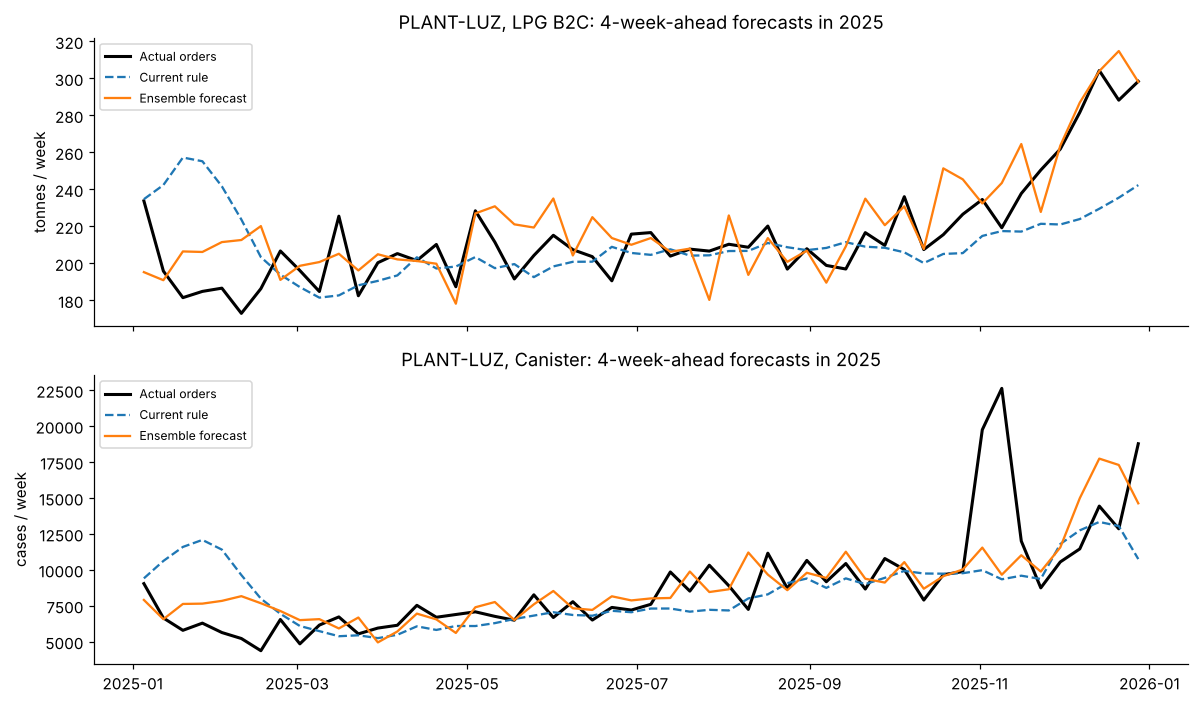

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
for ax, seg in zip(axes, FORECAST_LINES):
    d = test[(test.plant == "PLANT-LUZ") & (test.segment == seg)]
    scale, unit = (1000 / CANISTER_CASE_KG, "cases / week") if seg == "Canister" else (1, "tonnes / week")
    ax.plot(d["week"], d["order_t"] * scale, color="black", lw=2, label="Actual orders")
    ax.plot(d["week"], d["Current rule (4-week avg)"] * scale, ls="--", label="Current rule")
    ax.plot(d["week"], d["Ensemble"] * scale, label="Ensemble forecast")
    ax.set(title=f"PLANT-LUZ, {LABEL[seg]}: 4-week-ahead forecasts in 2025", ylabel=unit)
    ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()
fig.savefig(FIG / "weekly_forecast_luzon.png", bbox_inches="tight")
plt.show()

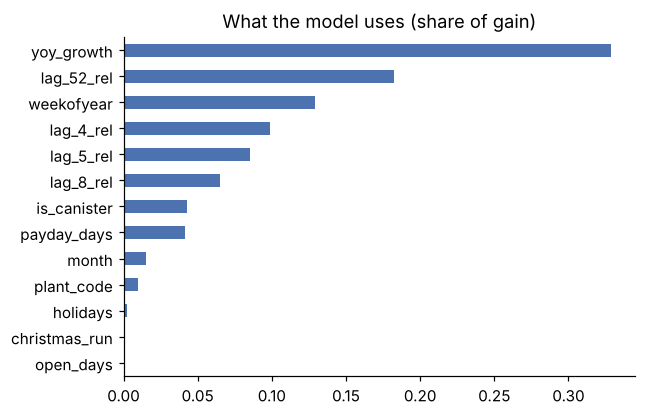

In [10]:
imp = pd.Series(model.booster_.feature_importance("gain"), index=FEATURES)
(imp / imp.sum()).sort_values().plot.barh(figsize=(6, 4), color="#4C72B0", title="What the model uses (share of gain)")
plt.show()

The model knows the season (week of year, December run, paydays, holidays) and last year's pattern, so it
anticipates the December and typhoon-season ramps. It cannot know *which* week a typhoon hits four weeks
in advance; those spikes need a short-term override from PAGASA typhoon bulletins.

## 1.5 Would a forecast-based plan cut stockouts?

Weekly approximation: plan = forecast x buffer. Demand above plan is unmet; production above it is excess.
A bigger buffer always trades fewer stockouts for more excess, so I compare plans across buffer levels:
the better plan leaves **less unmet demand for the same excess**. (Stock carried between weeks is ignored,
so this shows direction and size, not an exact plant simulation.)

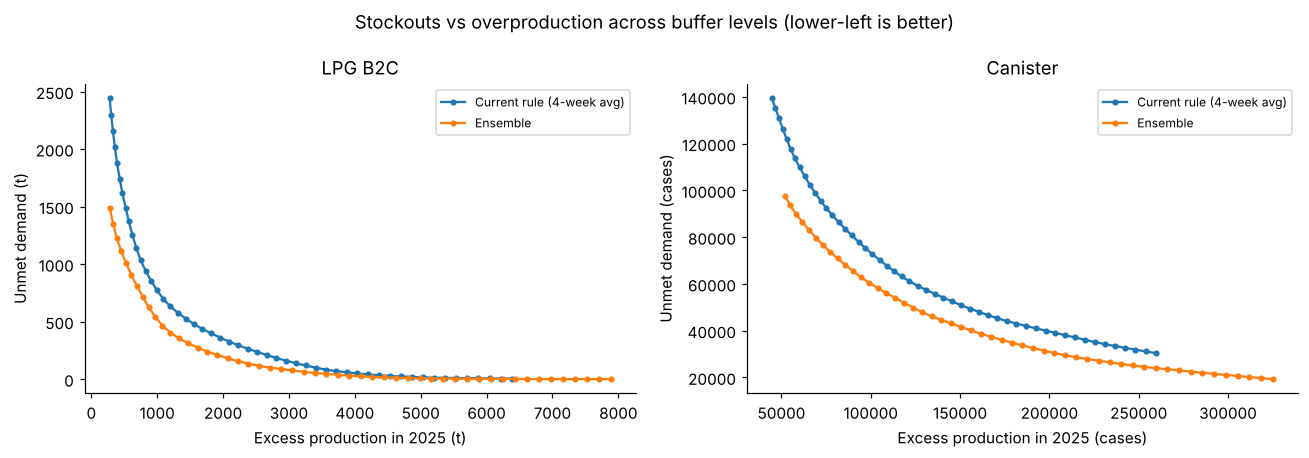

,unit,"unmet, current rule (3% buffer)","unmet, ensemble at same excess",reduction,"Dec unmet, current rule","Dec unmet, ensemble"
line,,,,,,
LPG B2C,t,854.0,594.8,30%,348.4,13.8
Canister,cases,"89,344.3","72,856.0",18%,"15,027.6","5,459.4"


In [11]:
buffers = np.round(np.arange(0.90, 1.41, 0.01), 2)

def curve(d, col):
    return pd.DataFrame([(np.clip(d["order_t"] - d[col] * b, 0, None).sum(),
                          np.clip(d[col] * b - d["order_t"], 0, None).sum()) for b in buffers],
                        index=buffers, columns=["unmet_t", "excess_t"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
summary = []
for ax, seg in zip(axes, FORECAST_LINES):
    d = test[test.segment == seg]
    scale, unit = (1000 / CANISTER_CASE_KG, "cases") if seg == "Canister" else (1, "t")
    curves = {mm: curve(d, mm) for mm in ["Current rule (4-week avg)", "Ensemble"]}
    for mm, c in curves.items():
        ax.plot(c["excess_t"] * scale, c["unmet_t"] * scale, marker=".", label=mm)
    ax.set(title=LABEL[seg], xlabel=f"Excess production in 2025 ({unit})", ylabel=f"Unmet demand ({unit})")
    ax.legend(fontsize=8)
    cur = curves["Current rule (4-week avg)"].loc[1.03]
    ens = curves["Ensemble"].sort_values("excess_t")
    same = np.interp(cur["excess_t"], ens["excess_t"], ens["unmet_t"])
    dec = d.week.dt.month == 12
    summary.append({"line": LABEL[seg], "unit": unit,
                    "unmet, current rule (3% buffer)": cur["unmet_t"] * scale,
                    "unmet, ensemble at same excess": same * scale,
                    "reduction": f"{1 - same / cur['unmet_t']:.0%}",
                    "Dec unmet, current rule": np.clip(d.loc[dec, "order_t"] - d.loc[dec, "Current rule (4-week avg)"] * 1.03, 0, None).sum() * scale,
                    "Dec unmet, ensemble": np.clip(d.loc[dec, "order_t"] - d.loc[dec, "Ensemble"] * 1.03, 0, None).sum() * scale})
fig.suptitle("Stockouts vs overproduction across buffer levels (lower-left is better)")
fig.tight_layout()
fig.savefig(FIG / "production_tradeoff.png", bbox_inches="tight")
plt.show()
pd.DataFrame(summary).set_index("line")

## 1.6 Next 4 weeks: what to prepare

The model only needs data at least 4 weeks old, so it can forecast the first 4 weeks of 2026 now.
LPG tonnes are split into cylinder sizes using each plant's B2C mix over the last 13 weeks.

In [12]:
future_weeks = pd.date_range("2026-01-04", periods=HORIZON, freq="W-SUN")
future = weekly[["plant", "segment"]].drop_duplicates().merge(pd.DataFrame({"week": future_weeks}), how="cross")
future["order_t"] = np.nan
ext = add_features(pd.concat([weekly, future], ignore_index=True))
ext = ext[ext["week"].isin(future_weeks)].copy()
ext["forecast_t"] = (predict_lgbm(model, ext) + ext["lag_52_rel"] * ext["level"] * ext["yoy_growth"]) / 2

recent = visits[(visits["date"] > "2025-10-01") & (visits["withdrew"] == 1) & (visits["segment"] == "B2C")]
kg_by_size = recent.groupby("plant")[list(CYL_SIZES)].sum().mul(pd.Series(CYL_SIZES))
kg_share = kg_by_size.div(kg_by_size.sum(axis=1), axis=0)

lpg_plan = ext[ext.segment == "B2C"].groupby("plant")["forecast_t"].sum().to_frame("LPG B2C tonnes")
for col, kg in CYL_SIZES.items():
    lpg_plan[col.replace("qty_", "").replace("_", ".") + " cylinders"] = (
        lpg_plan["LPG B2C tonnes"] * 1000 * kg_share[col] / kg).round(-1)
lpg_plan["Canister cases"] = (ext[ext.segment == "Canister"].groupby("plant")["forecast_t"].sum()
                              * 1000 / CANISTER_CASE_KG).round(-1)
print("Forecast-based plan, 4 weeks ending 25 Jan 2026 (LPG B2C + Canister)")
lpg_plan.round(0).astype(int)

Forecast-based plan, 4 weeks ending 25 Jan 2026 (LPG B2C + Canister)


,LPG B2C tonnes,2.7kg cylinders,11kg cylinders,22kg cylinders,50kg cylinders,Canister cases
plant,,,,,,
PLANT-LUZ,925,16540,71750,1660,1100,40120
PLANT-MIN,236,4700,18190,470,250,8280
PLANT-VIS,294,5110,23000,560,290,9030


**LPG B2B** is added on top from the SPANCOP pipeline: accounts in the *Order* and *Payment* stages are
firm volume, and *Close* can be added with a win-probability weight. Total LPG to fill = B2C forecast
+ B2B committed volume + safety buffer.

## 1.7 Takeaways

- **Forecast orders, not withdrawals.** Withdrawals hide the demand lost to stockouts.
- For **LPG B2C**, the ensemble beats the current 4-week-average rule (WAPE 8.8% vs 10.4%), with the
  biggest gain in **December** (5.7% vs 21.4%), when stockouts peak.
- **Canisters are harder to forecast weekly** (WAPE ~23% vs ~9% for LPG B2C): fewer, larger orders and
  typhoon spikes that land in random weeks. The forecast still beats the current rule overall, but not in
  every month. For canisters I would plan **monthly**, build warehouse stock **before** the typhoon season,
  and override the plan when PAGASA issues a typhoon warning.
- Canister peaks (typhoon season, December) do not line up with LPG's, so the two lines need separate plans.
- The plan is turned into **cylinders per size** and **canister cases**, concrete targets for the
  filling line and warehouse.